# Phase 1 — Exploratory Data Analysis

## Purpose

this notebook explores the cleaned Roman Urdu data w simple tables nd charts.
It focuses on class balance, sentence lengths, common words, and their relationships
btw numeric text-length features.

In [1]:
from pathlib import Path
import os

# this makes the notebook work whether it is opened from the project folder
# or from inside the notebooks folder.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
IMAGES = PROJECT_ROOT / "images"

DATA_RAW.mkdir(parents=True, exist_ok=True)
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
IMAGES.mkdir(parents=True, exist_ok=True)

# Store the downloaded Hugging Face files inside this project.
os.environ["HF_HOME"] = str(PROJECT_ROOT / ".cache" / "huggingface")

print("Project folder:", PROJECT_ROOT)

Project folder: E:\AssDS\Project


In [2]:
from collections import Counter
import re

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 100)

df = pd.read_csv(DATA_PROCESSED / "roman_urdu_cleaned.csv")
print("Cleaned data shape:", df.shape)
df.head()

Cleaned data shape: (19490, 5)


,sentence,sentiment,clean_text,character_count,word_count
0,Sai kha ya her kisi kay bus ki bat nhi hai lakin main ki hal kal bi Aj aur aj bi sirf Aus say bus,Positive,sai kha ya her kisi kay bus ki bat nhi hai lakin main ki hal kal bi aj aur aj bi sirf aus say bus,97,25
1,sahi bt h,Positive,sahi bt h,9,3
2,"Kya bt hai,",Positive,"kya bt hai,",11,3
3,Wah je wah,Positive,wah je wah,10,3
4,Are wha kaya bat hai,Positive,are wha kaya bat hai,20,5


## 1. Class distribution

In [3]:
class_counts = df["sentiment"].value_counts()
class_percentages = (df["sentiment"].value_counts(normalize=True) * 100).round(2)

class_summary = pd.DataFrame(
    {"count": class_counts, "percentage": class_percentages}
)
class_summary

,count,percentage
sentiment,,
Neutral,8446,43.34
Positive,5810,29.81
Negative,5234,26.85


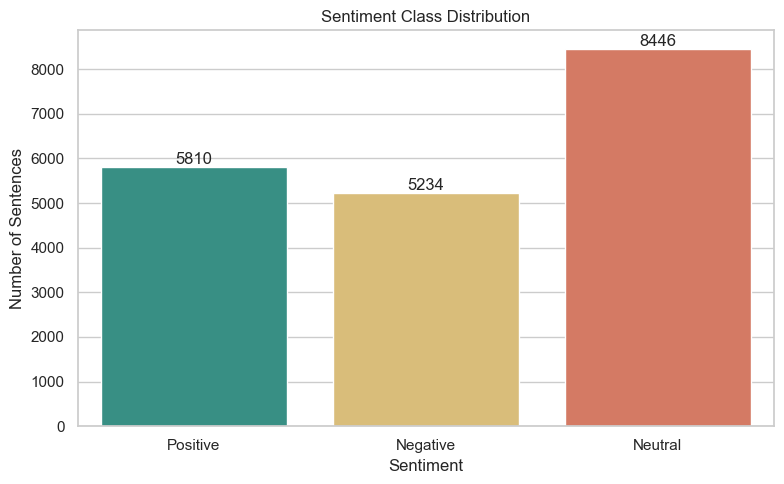

In [4]:
class_order = ["Positive", "Negative", "Neutral"]
colors = ["#2a9d8f", "#e76f51", "#e9c46a"]

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x="sentiment", order=class_order, palette=colors, hue="sentiment", legend=False)
plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Sentences")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.savefig(IMAGES / "01_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

the chart checks class imbalance. accuracy alone can be misleading if one class is
much larger, so Phase 2 should also report macro precision, recall, and f1-score.

## 2. Sentence-length distributions

In [5]:
# Recalculate to show exactly how these simple features are made.
df["character_count"] = df["clean_text"].str.len()
df["word_count"] = df["clean_text"].str.split().str.len()
df["average_word_length"] = (
    df["character_count"] / df["word_count"].replace(0, 1)
)
df["punctuation_count"] = df["sentence"].str.count(r"[^\w\s]")

df.groupby("sentiment")[["word_count", "character_count"]].agg(
    ["mean", "median", "max"]
).round(2)

word_count             character_count             
                mean median  max            mean median   max
sentiment                                                    
Negative       15.44   11.0  295           77.83   56.0  2017
Neutral        10.44    8.0  144           52.82   36.0   791
Positive       16.37   12.0  301           84.73   62.0  1428

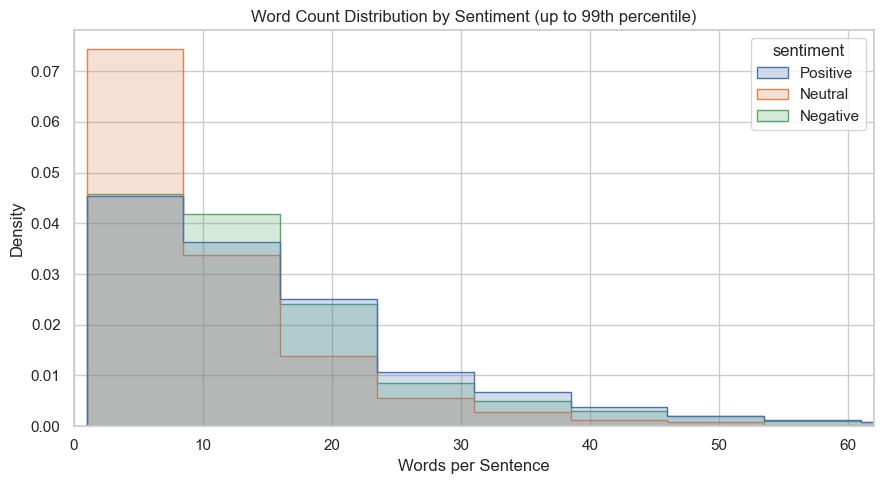

In [6]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="word_count", hue="sentiment", bins=40, element="step", stat="density", common_norm=False)
plt.xlim(0, df["word_count"].quantile(0.99))
plt.title("Word Count Distribution by Sentiment (up to 99th percentile)")
plt.xlabel("Words per Sentence")
plt.ylabel("Density")
plt.tight_layout()
plt.savefig(IMAGES / "02_word_count_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

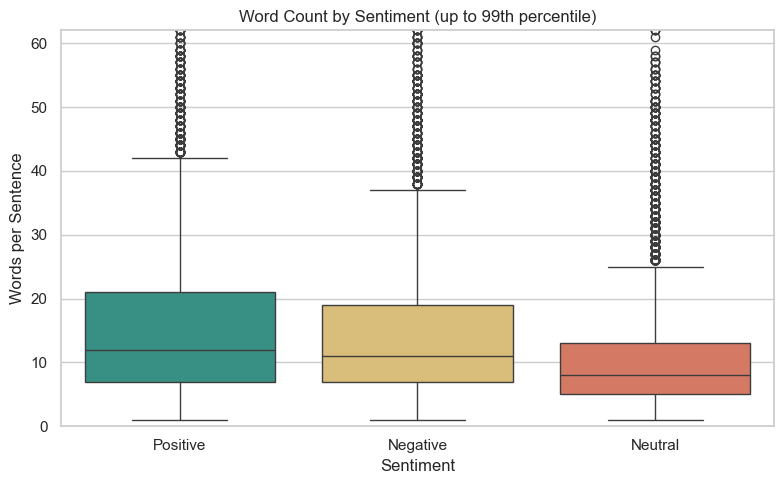

In [7]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="sentiment", y="word_count", order=class_order, palette=colors, hue="sentiment", legend=False)
plt.ylim(0, df["word_count"].quantile(0.99))
plt.title("Word Count by Sentiment (up to 99th percentile)")
plt.xlabel("Sentiment")
plt.ylabel("Words per Sentence")
plt.tight_layout()
plt.savefig(IMAGES / "03_word_count_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Most common words

In [8]:
def get_words(text_series):
    # Return simple alphabetic Roman Urdu tokens from a group of sentences.
    all_text = " ".join(text_series.astype(str))
    return re.findall(r"[a-zA-Z]+", all_text.lower())


top_words_by_sentiment = {}
for sentiment in class_order:
    words = get_words(df.loc[df["sentiment"] == sentiment, "clean_text"])
    top_words_by_sentiment[sentiment] = Counter(words).most_common(15)

pd.DataFrame(
    {
        sentiment: [f"{word} ({count})" for word, count in values]
        for sentiment, values in top_words_by_sentiment.items()
    }
)

,Positive,Negative,Neutral
0,ki (2428),ki (1605),ke (1794)
1,ke (2424),hai (1245),ki (1665)
2,mein (1837),ko (1206),mein (1640)
3,hai (1491),k (1158),hai (1153)
4,aur (1486),ke (1096),ka (1111)
5,ka (1347),ka (1093),se (1029)
6,ko (1330),se (915),ko (1006)
7,se (1252),mein (838),aur (927)
8,ne (898),aur (718),k (787)
9,k (825),ho (655),ne (660)


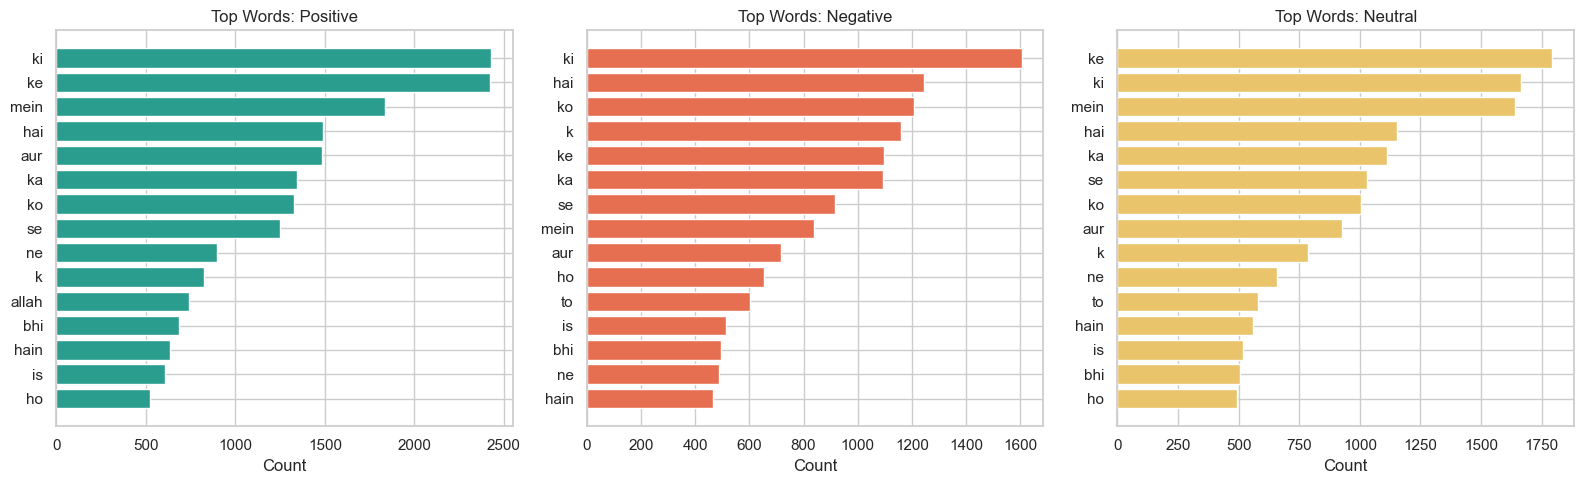

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for axis, sentiment, color in zip(axes, class_order, colors):
    word_counts = top_words_by_sentiment[sentiment][::-1]
    words = [item[0] for item in word_counts]
    counts = [item[1] for item in word_counts]
    axis.barh(words, counts, color=color)
    axis.set_title(f"Top Words: {sentiment}")
    axis.set_xlabel("Count")

plt.tight_layout()
plt.savefig(IMAGES / "04_top_words_by_sentiment.png", dpi=150, bbox_inches="tight")
plt.show()

Common words are retained here because a reliable Roman Urdu stop-word list is not
available in the dataset. In Phase 2, TF-IDF can reduce the influence of words that
appear everywhere, while n-grams can preserve short sentiment phrases.

## 4. Correlation heatmap for derived numeric features

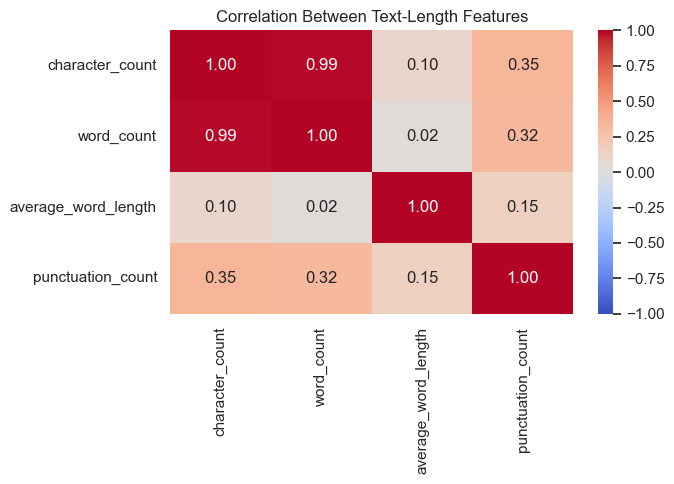

,character_count,word_count,average_word_length,punctuation_count
character_count,1.000000,0.988832,0.096979,0.350833
word_count,0.988832,1.000000,0.024541,0.322264
average_word_length,0.096979,0.024541,1.000000,0.154061
punctuation_count,0.350833,0.322264,0.154061,1.000000


In [10]:
numeric_columns = [
    "character_count",
    "word_count",
    "average_word_length",
    "punctuation_count",
]
correlations = df[numeric_columns].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(correlations, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Between Text-Length Features")
plt.tight_layout()
plt.savefig(IMAGES / "05_feature_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

correlations

## 5. automatically calculated key findings

In [11]:
largest_class = class_counts.idxmax()
smallest_class = class_counts.idxmin()
imbalance_ratio = class_counts.max() / class_counts.min()
median_words = df["word_count"].median()
short_share = (df["word_count"] <= 5).mean() * 100
long_share = (df["word_count"] > 20).mean() * 100

print(f"1. the largest class is {largest_class} ({class_counts[largest_class]:,} rows).")
print(f"2. the smallest class is {smallest_class} ({class_counts[smallest_class]:,} rows).")
print(f"3. largest-to-smallest class ratio: {imbalance_ratio:.2f}:1.")
print(f"4. median sentence length: {median_words:.0f} words.")
print(f"5. sentences with 5 words or fewer: {short_share:.1f}%.")
print(f"6. sentences longer than 20 words: {long_share:.1f}%.")
print("7. character count and word count are expected to be strongly related; both should not automatically be treated as independent signals.")

1. The largest class is Neutral (8,446 rows).
2. The smallest class is Negative (5,234 rows).
3. Largest-to-smallest class ratio: 1.61:1.
4. Median sentence length: 10 words.
5. Sentences with 5 words or fewer: 23.7%.
6. Sentences longer than 20 words: 18.5%.
7. Character count and word count are expected to be strongly related; both should not automatically be treated as independent signals.


## EDA conclusion

The dataset contains short, informal Roman Urdu text and a noticeable class
imbalance. Phase 2 should use a stratified split, compare macro-F1 as well as
accuracy, and consider word and character n-grams because spellings vary.